# ERA5 Wind Speed Calibration: Smooth Linear Regression with Lags

This notebook implements and evaluates an advanced, continuous calibration method for translating **ERA5 10m wind speed** to **ground-based weather station measurements** at the ALMA site. 

### Why This Approach?
While the discrete **Diurnal-Sector Calibration** (using independent slope/intercept regression lines for 192 hour-sector bins) improves accuracy, it suffers from:
1. **Boundary Discontinuities:** Artificial jumps in calibration when the wind direction shifts by a fraction of a degree near sector boundaries.
2. **Data Sparsity:** High variance and overfitting in rarely observed time/direction bins.

### The Algorithm: Smooth Linear Regression with Lags
Instead of binning, we use a single global Ridge regression model that handles direction, time-of-day, and seasonality as continuous, smooth cyclic functions, and incorporates temporal lags:
* **Lag & Lead Features ($t-1$, $t+1$):** Accounts for spatial/temporal phase shifts of wind fronts between the global model grids and local observations.
* **Continuous Direction (u, v vectors):** Models wind direction using continuous wind speed components rather than arbitrary discrete sectors.
* **Cyclic Harmonics (sine/cosine):** Models diurnal and seasonal cycles smoothly without step-changes between hours or months.
* **Interaction Terms:** Allows the scaling factor to change dynamically based on direction and time of day.

In [1]:
# ============================================================
# 1. IMPORTS & CONFIGURATION
# ============================================================
import os
import glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge

plt.style.use('default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
print("Libraries loaded successfully! ✔")

Libraries loaded successfully! ✔


In [2]:
# ============================================================
# 2. LOAD PUBLISHED GROUND-BASED DATA
# ============================================================
pub_path = r"../data/exports/alma_published_timeseries.csv"
df_pub = pd.read_csv(pub_path, parse_dates=['datetime'])

# Drop rows with missing speed values
df_pub = df_pub.dropna(subset=['speed'])
print(f"Loaded {len(df_pub):,} valid ground-based hourly records.")

Loaded 15,632 valid ground-based hourly records.


In [3]:
# ============================================================
# 3. LOAD ERA5 DATA WITH WIND COMPONENTS
# ============================================================
ALMA_LAT = -23.029
ALMA_LON = -67.755

chile_files = sorted(glob.glob(r"../data/raw/chile/chile_*.nc"))
print(f"Found {len(chile_files)} ERA5 NetCDF files.")

era5_records = []
for f in chile_files:
    with xr.open_dataset(f) as ds:
        point_ds = ds.sel(latitude=ALMA_LAT, longitude=ALMA_LON, method='nearest')
        u10 = point_ds['u10'].values
        v10 = point_ds['v10'].values
        ws10 = np.sqrt(u10**2 + v10**2)
        
        df_pt = pd.DataFrame({
            'datetime': point_ds['valid_time'].values,
            'era5_speed': ws10,
            'era5_u10': u10,
            'era5_v10': v10
        })
        era5_records.append(df_pt)

df_era5 = pd.concat(era5_records, ignore_index=True)
df_era5 = df_era5.sort_values('datetime').reset_index(drop=True)
print(f"Loaded {len(df_era5):,} ERA5 hourly records.")

Found 24 ERA5 NetCDF files.


Loaded 17,520 ERA5 hourly records.


In [4]:
# ============================================================
# 4. FEATURE ENGINEERING (LAGS, CYCLIC TIME, INTERACTIONS)
# ============================================================
# Compute temporal lag/lead features on continuous ERA5 data first
for lag in [1, 2]:
    df_era5[f'era5_speed_lag{lag}'] = df_era5['era5_speed'].shift(lag)
    df_era5[f'era5_speed_lead{lag}'] = df_era5['era5_speed'].shift(-lag)
    df_era5[f'era5_u10_lag{lag}'] = df_era5['era5_u10'].shift(lag)
    df_era5[f'era5_u10_lead{lag}'] = df_era5['era5_u10'].shift(-lag)
    df_era5[f'era5_v10_lag{lag}'] = df_era5['era5_v10'].shift(lag)
    df_era5[f'era5_v10_lead{lag}'] = df_era5['era5_v10'].shift(-lag)

# Time features
df_era5['hour'] = df_era5['datetime'].dt.hour
df_era5['month'] = df_era5['datetime'].dt.month

# Sine and Cosine transformations for smooth diurnal & seasonal cycles
h_rad = 2 * np.pi * df_era5['hour'] / 24.0
m_rad = 2 * np.pi * df_era5['month'] / 12.0
df_era5['sin_hour'] = np.sin(h_rad)
df_era5['cos_hour'] = np.cos(h_rad)
df_era5['sin_hour_2'] = np.sin(2 * h_rad)  # 12-hour harmonic
df_era5['cos_hour_2'] = np.cos(2 * h_rad)
df_era5['sin_month'] = np.sin(m_rad)
df_era5['cos_month'] = np.cos(m_rad)

# Cross/Interaction terms to allow speed scaling factor to vary continuously
df_era5['ws_sin_hour'] = df_era5['era5_speed'] * df_era5['sin_hour']
df_era5['ws_cos_hour'] = df_era5['era5_speed'] * df_era5['cos_hour']
df_era5['ws_u10'] = df_era5['era5_speed'] * df_era5['era5_u10']
df_era5['ws_v10'] = df_era5['era5_speed'] * df_era5['era5_v10']

print("Feature engineering complete.")

Feature engineering complete.


In [5]:
# ============================================================
# 5. ALIGN DATASETS AND REMOVE BOUNDARY NANs
# ============================================================
merged_df = pd.merge(df_pub, df_era5, on='datetime', how='inner')
merged_df = merged_df.dropna(subset=['speed', 'era5_speed'])
lag_cols = [c for c in merged_df.columns if 'lag' in c or 'lead' in c]
merged_df = merged_df.dropna(subset=lag_cols).sort_values('datetime').reset_index(drop=True)

print(f'Aligned dataset size: {len(merged_df):,} records.')


Aligned dataset size: 15,628 records.


In [6]:
# ============================================================
# 6. FIT DIURNAL-SECTOR CALIBRATION MODEL (FOR COMPARISON)
# ============================================================
merged_df['era5_dir'] = (np.degrees(np.arctan2(-merged_df['era5_u10'], -merged_df['era5_v10'])) + 360) % 360

def get_sector(deg):
    if (deg >= 337.5) or (deg < 22.5): return 'N'
    elif (deg >= 22.5) and (deg < 67.5): return 'NE'
    elif (deg >= 67.5) and (deg < 112.5): return 'E'
    elif (deg >= 112.5) and (deg < 157.5): return 'SE'
    elif (deg >= 157.5) and (deg < 202.5): return 'S'
    elif (deg >= 202.5) and (deg < 247.5): return 'SW'
    elif (deg >= 247.5) and (deg < 292.5): return 'W'
    else: return 'NW'

merged_df['sector'] = merged_df['era5_dir'].apply(get_sector)

slopes = {}
intercepts = {}
global_slope, global_intercept = np.polyfit(merged_df['era5_speed'], merged_df['speed'], 1)

for (h, sec), group in merged_df.groupby(['hour', 'sector']):
    if len(group) > 5:
        slopes[(h, sec)], intercepts[(h, sec)] = np.polyfit(group['era5_speed'], group['speed'], 1)
    else:
        slopes[(h, sec)], intercepts[(h, sec)] = global_slope, global_intercept

def apply_diurnal_sector(row):
    h = row['hour']
    sec = row['sector']
    s = slopes.get((h, sec), global_slope)
    i = intercepts.get((h, sec), global_intercept)
    return s * row['era5_speed'] + i

merged_df['era5_speed_diurnal_sector'] = merged_df.apply(apply_diurnal_sector, axis=1)
print("Diurnal-Sector Calibration model fitted.")

Diurnal-Sector Calibration model fitted.


In [7]:
# ============================================================
# 7. FIT SMOOTH LINEAR MODEL WITH LAGS & CYCLIC TIME
# ============================================================
X_cols = [
    'era5_speed', 'era5_u10', 'era5_v10',
    'era5_speed_lag1', 'era5_u10_lag1', 'era5_v10_lag1',
    'era5_speed_lead1', 'era5_u10_lead1', 'era5_v10_lead1',
    'sin_hour', 'cos_hour', 'sin_hour_2', 'cos_hour_2', 'sin_month', 'cos_month',
    'ws_sin_hour', 'ws_cos_hour', 'ws_u10', 'ws_v10'
]

# Ridge regression (L2 regularization) with alpha=1.0 avoids extreme weights
reg = Ridge(alpha=1.0)
reg.fit(merged_df[X_cols], merged_df['speed'])

merged_df['era5_speed_smooth_linear'] = reg.predict(merged_df[X_cols])
print(f"Smooth Linear Calibration model fitted successfully! ✔")
print(f"Model R² score on all aligned data: {reg.score(merged_df[X_cols], merged_df['speed']):.4f}")

Smooth Linear Calibration model fitted successfully! ✔
Model R² score on all aligned data: 0.6276


In [8]:
# ============================================================
# 8. EVALUATE COMPARISON METRICS
# ============================================================
def calc_metrics(pred, truth):
    diff = pred - truth
    rmse = np.sqrt((diff ** 2).mean())
    bias = diff.mean()
    mae = diff.abs().mean()
    corr = truth.corr(pd.Series(pred, index=truth.index))
    return bias, mae, rmse, corr

metrics_orig = calc_metrics(merged_df['era5_speed'], merged_df['speed'])
metrics_diurnal = calc_metrics(merged_df['era5_speed_diurnal_sector'], merged_df['speed'])
metrics_smooth = calc_metrics(merged_df['era5_speed_smooth_linear'], merged_df['speed'])

df_metrics = pd.DataFrame({
    'Metric': ['Mean Bias Error (MBE)', 'Mean Absolute Error (MAE)', 'Root Mean Sq. Error (RMSE)', 'Pearson Correlation (R)'],
    'Original ERA5': metrics_orig,
    'Diurnal-Sector Calibrated': metrics_diurnal,
    'Smooth Linear Calibrated': metrics_smooth
})
print("--- Model Evaluation Table ---")
print(df_metrics.to_string(index=False))

--- Model Evaluation Table ---
                    Metric  Original ERA5  Diurnal-Sector Calibrated  Smooth Linear Calibrated
     Mean Bias Error (MBE)      -4.062479                  -0.010693             -7.420052e-16
 Mean Absolute Error (MAE)       4.124606                   1.944204              1.778384e+00
Root Mean Sq. Error (RMSE)       5.030037                   2.562619              2.396225e+00
   Pearson Correlation (R)       0.673396                   0.757708              7.922277e-01


In [9]:
# ============================================================
# 9. PERCENTILE COMPARISON TABLE
# ============================================================
percentiles = [50, 90, 95, 99]
pub_pcts = [merged_df['speed'].quantile(p/100) for p in percentiles]
era5_orig_pcts = [merged_df['era5_speed'].quantile(p/100) for p in percentiles]
era5_diurnal_pcts = [merged_df['era5_speed_diurnal_sector'].quantile(p/100) for p in percentiles]
era5_smooth_pcts = [merged_df['era5_speed_smooth_linear'].quantile(p/100) for p in percentiles]

df_pct = pd.DataFrame({
    'Percentile': [f'P{p}' for p in percentiles],
    'Ground-Based (m/s)': pub_pcts,
    'Original ERA5 (m/s)': era5_orig_pcts,
    'Diurnal-Sector (m/s)': era5_diurnal_pcts,
    'Smooth Linear (m/s)': era5_smooth_pcts,
    'Smooth Linear Error (m/s)': [s - g for g, s in zip(pub_pcts, era5_smooth_pcts)]
})
print("--- Percentile Calibration Table ---")
print(df_pct.to_string(index=False))

--- Percentile Calibration Table ---
Percentile  Ground-Based (m/s)  Original ERA5 (m/s)  Diurnal-Sector (m/s)  Smooth Linear (m/s)  Smooth Linear Error (m/s)
       P50                 6.0             1.867877              5.880516             5.824036                  -0.175964
       P90                11.8             5.788694             10.916605            10.830935                  -0.969065
       P95                13.6             6.545758             11.789089            12.357426                  -1.242574
       P99                17.6             8.061865             13.866980            15.850858                  -1.749142


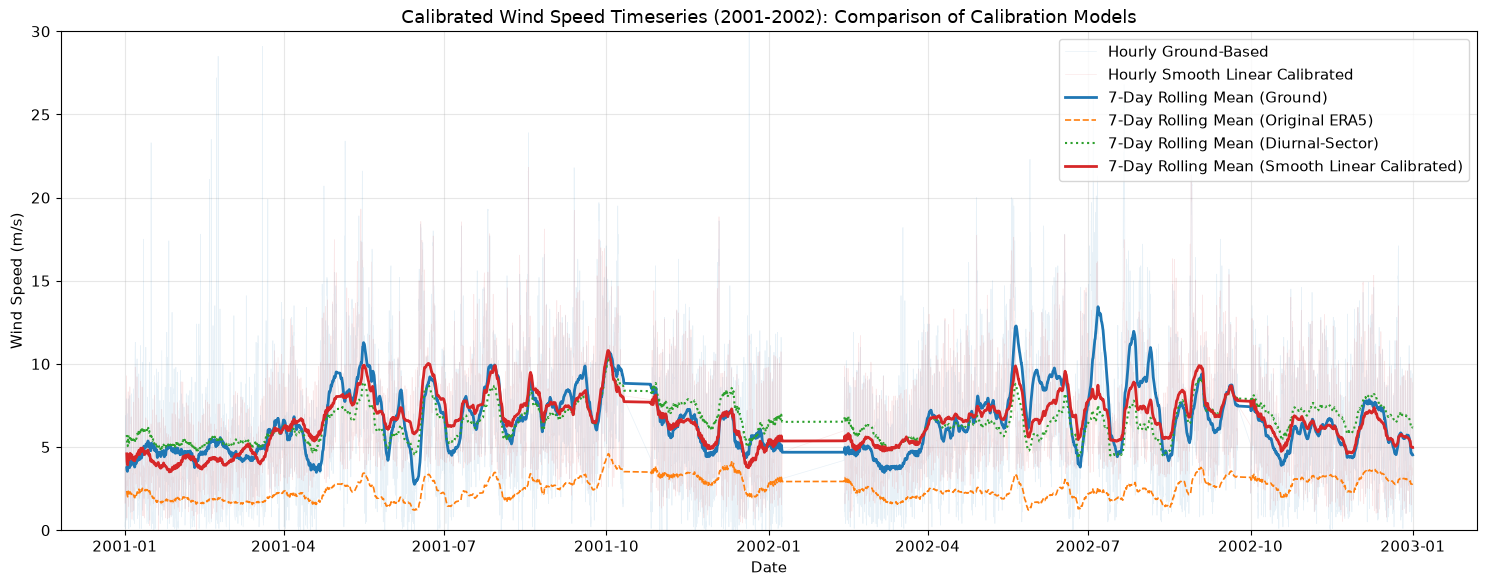

In [10]:
# ============================================================
# 10. TIMESERIES ROLLING MEAN COMPARISON PLOT
# ============================================================
plt.figure(figsize=(15, 6))
plt.plot(merged_df['datetime'], merged_df['speed'], color='#1f77b4', alpha=0.1, label='Hourly Ground-Based', linewidth=0.5)
plt.plot(merged_df['datetime'], merged_df['era5_speed_smooth_linear'], color='#d62728', alpha=0.1, label='Hourly Smooth Linear Calibrated', linewidth=0.5)

roll_window = 168  # 7-day rolling mean
plt.plot(merged_df['datetime'], merged_df['speed'].rolling(roll_window, min_periods=24).mean(), 
         color='#1f77b4', label='7-Day Rolling Mean (Ground)', linewidth=2.0)
plt.plot(merged_df['datetime'], merged_df['era5_speed'].rolling(roll_window, min_periods=24).mean(), 
         color='#ff7f0e', label='7-Day Rolling Mean (Original ERA5)', linewidth=1.2, linestyle='--')
plt.plot(merged_df['datetime'], merged_df['era5_speed_diurnal_sector'].rolling(roll_window, min_periods=24).mean(), 
         color='#2ca02c', label='7-Day Rolling Mean (Diurnal-Sector)', linewidth=1.5, linestyle=':')
plt.plot(merged_df['datetime'], merged_df['era5_speed_smooth_linear'].rolling(roll_window, min_periods=24).mean(), 
         color='#d62728', label='7-Day Rolling Mean (Smooth Linear Calibrated)', linewidth=2.0)

plt.title('Calibrated Wind Speed Timeseries (2001-2002): Comparison of Calibration Models')
plt.xlabel('Date')
plt.ylabel('Wind Speed (m/s)')
plt.legend(loc='upper right')
plt.ylim(0, 30)
plt.tight_layout()
plt.savefig('../data/exports/smooth_linear_timeseries_comparison.png', dpi=150)
plt.show()

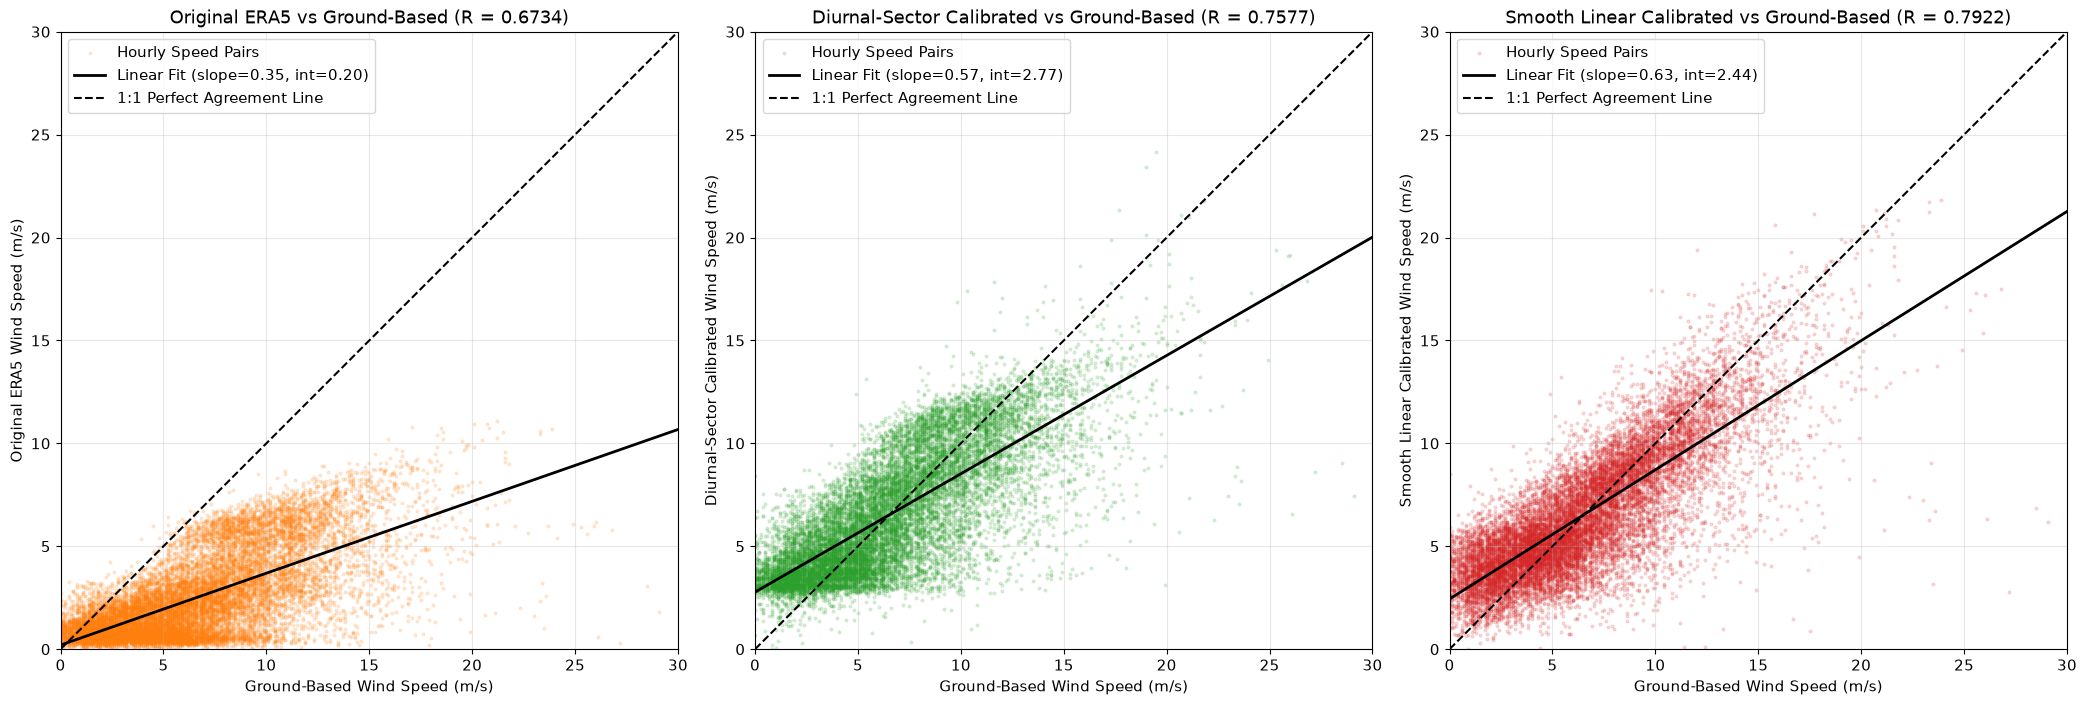

In [11]:
# ============================================================
# 11. SCATTER PLOTS & CORRELATION COMPARISONS
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
x_vals = np.linspace(0, 30, 100)

models_pred = [
    ('Original ERA5', merged_df['era5_speed'], '#ff7f0e'),
    ('Diurnal-Sector Calibrated', merged_df['era5_speed_diurnal_sector'], '#2ca02c'),
    ('Smooth Linear Calibrated', merged_df['era5_speed_smooth_linear'], '#d62728')
]

for idx, (title, pred, color) in enumerate(models_pred):
    axes[idx].scatter(merged_df['speed'], pred, alpha=0.15, s=4, color=color, label='Hourly Speed Pairs')
    s_fit, i_fit = np.polyfit(merged_df['speed'], pred, 1)
    axes[idx].plot(x_vals, s_fit * x_vals + i_fit, color='#000000', linewidth=2.0, 
                  label=f'Linear Fit (slope={s_fit:.2f}, int={i_fit:.2f})')
    axes[idx].plot([0, 30], [0, 30], 'k--', label='1:1 Perfect Agreement Line', linewidth=1.5)
    
    corr = merged_df['speed'].corr(pd.Series(pred, index=merged_df.index))
    axes[idx].set_title(f'{title} vs Ground-Based (R = {corr:.4f})')
    axes[idx].set_xlabel('Ground-Based Wind Speed (m/s)')
    axes[idx].set_ylabel(f'{title} Wind Speed (m/s)')
    axes[idx].set_xlim(0, 30)
    axes[idx].set_ylim(0, 30)
    axes[idx].set_aspect('equal', adjustable='box')
    axes[idx].legend(loc='upper left')

plt.tight_layout()
plt.savefig('../data/exports/smooth_linear_scatter_comparison.png', dpi=150)
plt.show()

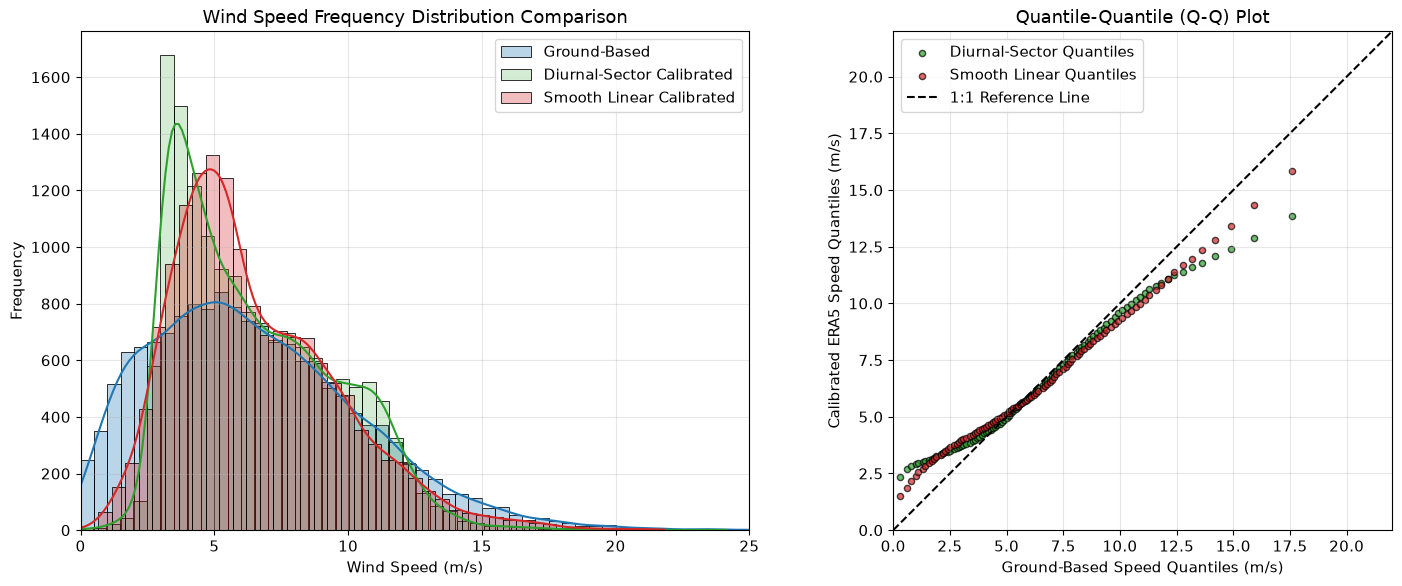

In [12]:
# ============================================================
# 12. FREQUENCY DISTRIBUTIONS & QUANTILE-QUANTILE (Q-Q) PLOTS
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Frequency distributions (Histograms / KDEs)
sns.histplot(merged_df['speed'], color='#1f77b4', alpha=0.3, label='Ground-Based', kde=True, binwidth=0.5, ax=axes[0])
sns.histplot(merged_df['era5_speed_diurnal_sector'], color='#2ca02c', alpha=0.2, label='Diurnal-Sector Calibrated', kde=True, binwidth=0.5, ax=axes[0])
sns.histplot(merged_df['era5_speed_smooth_linear'], color='#d62728', alpha=0.3, label='Smooth Linear Calibrated', kde=True, binwidth=0.5, ax=axes[0])
axes[0].set_title('Wind Speed Frequency Distribution Comparison')
axes[0].set_xlabel('Wind Speed (m/s)')
axes[0].set_ylabel('Frequency')
axes[0].set_xlim(0, 25)
axes[0].legend()

# Q-Q Plot
q_values = np.linspace(0.01, 0.99, 99)
q_pub = merged_df['speed'].quantile(q_values)
q_diurnal = merged_df['era5_speed_diurnal_sector'].quantile(q_values)
q_smooth = merged_df['era5_speed_smooth_linear'].quantile(q_values)

axes[1].scatter(q_pub, q_diurnal, color='#2ca02c', edgecolor='k', s=20, alpha=0.7, label='Diurnal-Sector Quantiles')
axes[1].scatter(q_pub, q_smooth, color='#d62728', edgecolor='k', s=20, alpha=0.7, label='Smooth Linear Quantiles')
axes[1].plot([0, 25], [0, 25], 'k--', label='1:1 Reference Line')
axes[1].set_title('Quantile-Quantile (Q-Q) Plot')
axes[1].set_xlabel('Ground-Based Speed Quantiles (m/s)')
axes[1].set_ylabel('Calibrated ERA5 Speed Quantiles (m/s)')
axes[1].set_xlim(0, 22)
axes[1].set_ylim(0, 22)
axes[1].set_aspect('equal', adjustable='box')
axes[1].legend()

plt.tight_layout()
plt.savefig('../data/exports/smooth_linear_distribution_comparison.png', dpi=150)
plt.show()